In [1]:
import sklearn
print(sklearn.__version__)

1.7.2


In [2]:
import numpy as np
import pandas as pd

**End-to-End ML Workflows with Scikit-learn**

Let's build a simple classification model with the
Titanic Dataset
Titanic Survival Prediction
Machine Learning Lifecycle
We will follow these steps:
1. Problem Definition
2. Data Collection and Preparation
3. Choosing a Model
4. Training the Models
5. Evaluation
6. Tuning & Optimization
7. Final Model Selection
8. Prediction

1. Problem Definition
The Titanic dataset contains information about passengers who were aboard the
Titanic. Our goal is to build a machine learning model that can predict whether a
passenger (would):

- Survived the Titanic ( 1 )
- Did not survive the Titanic ( 0 )
  
This is a classification problem because the output belongs to one of two categories.

In [3]:
# First, we import our libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

What are these libraries for?
- Pandas: working with datasets
- NumPy: numerical operations
- Matplotlib: creating charts/plots
- Scikit-learn: machine learning
- StandardScaler: scaling numerical data
- LogisticRegression: 1 classification model
- DecisionTreeClassifier: 2 classification model (decision tree)
- RandomForestClassifier: 3 classification model (random forest model)
- GridSearchCV: finding better model settings
- accuracy_score: measuring prediction accuracy
- classification_report: generate all report (accuracy, precision, etc)
- confusion_matrix: generate confusion matrix

**2. Data Collection and Preparation**

In [37]:
#import file

titanic_data = pd.read_csv('data/titanic.csv')
titanic_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,PaCh,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [38]:
titanic_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 887 entries, 0 to 886
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  887 non-null    int64  
 1   Pclass    887 non-null    int64  
 2   Name      887 non-null    object 
 3   Sex       887 non-null    object 
 4   Age       887 non-null    float64
 5   SibSp     887 non-null    int64  
 6   PaCh      887 non-null    int64  
 7   Fare      887 non-null    float64
dtypes: float64(2), int64(4), object(2)
memory usage: 55.6+ KB


Understanding the Dataset
Some important columns include:
- survived : whether the passenger survived
- pclass : passenger class
- sex : passenger's sex
- age : passenger's age
- sibsp : number of siblings/spouses aboard
- parch : number of parents/children aboard
- fare : ticket fare
- embarked : port where the passenger boarded
  
Our target variable is:
survived

The other useful columns will be used as features.

In [39]:
titanic_data.describe()

,Survived,Pclass,Age,SibSp,PaCh,Fare
count,887.000000,887.000000,887.000000,887.000000,887.000000,887.00000
mean,0.385569,2.305524,29.471443,0.525366,0.383315,32.30542
std,0.487004,0.836662,14.121908,1.104669,0.807466,49.78204
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.00000
25%,0.000000,2.000000,20.250000,0.000000,0.000000,7.92500
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.45420
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.13750
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.32920


In [40]:
titanic_data["Survived"].value_counts()

Survived
0    545
1    342
Name: count, dtype: int64

In [41]:
titanic_data.isnull().sum()

Survived    0
Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
PaCh        0
Fare        0
dtype: int64

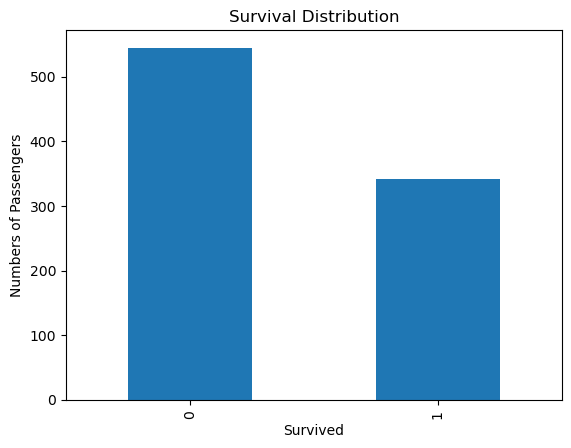

In [42]:
titanic_data["Survived"].value_counts().plot(kind="bar")
plt.title("Survival Distribution")
plt.xlabel("Survived")
plt.ylabel("Numbers of Passengers")

plt.show()

What are we looking for?
Before training a model, we should understand our data. We can ask questions such
as:
- How many passengers survived?
- How many passengers did not survive?
- Which columns contain missing values?
- Which columns are numerical?
- Which columns are categorical?

let's select the important features
We'll use:
- pclass
- sex
- age
- sibsp
- parch
- fare

In [43]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'PaCh', 'Fare']

target = 'Survived'

x = titanic_data[features].copy()
y = titanic_data[target].copy()

In [44]:
titanic_data.columns

Index(['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'PaCh', 'Fare'], dtype='object')

In [45]:
x.head() 

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,3,male,22.0,1,0,7.2500
1,1,female,38.0,1,0,71.2833
2,3,female,26.0,0,0,7.9250
3,1,female,35.0,1,0,53.1000
4,3,male,35.0,0,0,8.0500


In [46]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

Clean the Data
- Handle Missing Values
- Wrong formats
.
.
etc

**Convert Categorical Data**

Our machine learning models cannot directly work with text such as: Male and
Female. So, we need to convert them into numbers.

In [47]:
x['Sex'] = x['Sex'].apply(lambda x: 1 if x == 'female' else 0)

In [48]:
x.head()

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,3,0,22.0,1,0,7.2500
1,1,1,38.0,1,0,71.2833
2,3,1,26.0,0,0,7.9250
3,1,1,35.0,1,0,53.1000
4,3,0,35.0,0,0,8.0500


**There is a better way to do this: using one-hot encoding**



x = pd.get_dummies(
x,
columns=["Sex"],
drop_first=True
)

In [49]:
x.head()

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,3,0,22.0,1,0,7.2500
1,1,1,38.0,1,0,71.2833
2,3,1,26.0,0,0,7.9250
3,1,1,35.0,1,0,53.1000
4,3,0,35.0,0,0,8.0500


**Split the Dataset**

We should not train and test our model using exactly the same data. Instead, we
divide the dataset into:

- Training data: used to teach the model
- Testing data: used to evaluate the model on unseen data
  
We will use:
- 80% for training
- 20% for testing

In [50]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y) #random state is used for reproducibility

In [51]:
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (709, 6)
Testing data: (178, 6)


**Feature Scaling**

Some models aren't affected, but for Logistic Regression, scaling the numerical features is useful.

In [52]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

**Important**

We use:
fit_transform() on the training data

but only:
transform(): on the testing data

Why?
- The scaler should learn the scaling information from the training data only.
- The test data should remain unseen until evaluation.

**3. Choosing Our Models (Model Selection)**

We will compare three classification algorithms:

1. Logistic Regression

A simple and popular classification algorithm.

2. Decision Tree
   
Makes decisions by asking a series of questions about the data.

3. Random Forest
   
Combines multiple decision trees to make predictions.

We will train all three models and compare their performance.

In [53]:
# Train Logistic Regression
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(x_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [54]:
#Assignment

# Train Logistic Regression
logistic_model = LogisticRegression(max_iter=500)
logistic_model.fit(x_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,500
,multi_class,'deprecated'


In [55]:
logistic_predictions = logistic_model.predict(x_test_scaled)
logistic_accuracy = accuracy_score(
y_test,
logistic_predictions
)
print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.7696629213483146


In [56]:
logistic_predictions = logistic_model.predict(x_test)
logistic_accuracy = accuracy_score(
y_test,
logistic_predictions
)
print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.6348314606741573


C:\Users\Adeola\.anaconda\ANACONDA\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


**22/09/2026**

In [57]:
print(classification_report(y_test, logistic_predictions))

              precision    recall  f1-score   support

           0       0.64      0.94      0.76       109
           1       0.62      0.14      0.24        69

    accuracy                           0.63       178
   macro avg       0.63      0.54      0.50       178
weighted avg       0.63      0.63      0.56       178



In [58]:
# Train Decision Tree  
tree_model = DecisionTreeClassifier(
    max_depth=3,    
    random_state=42
)

tree_model.fit(x_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


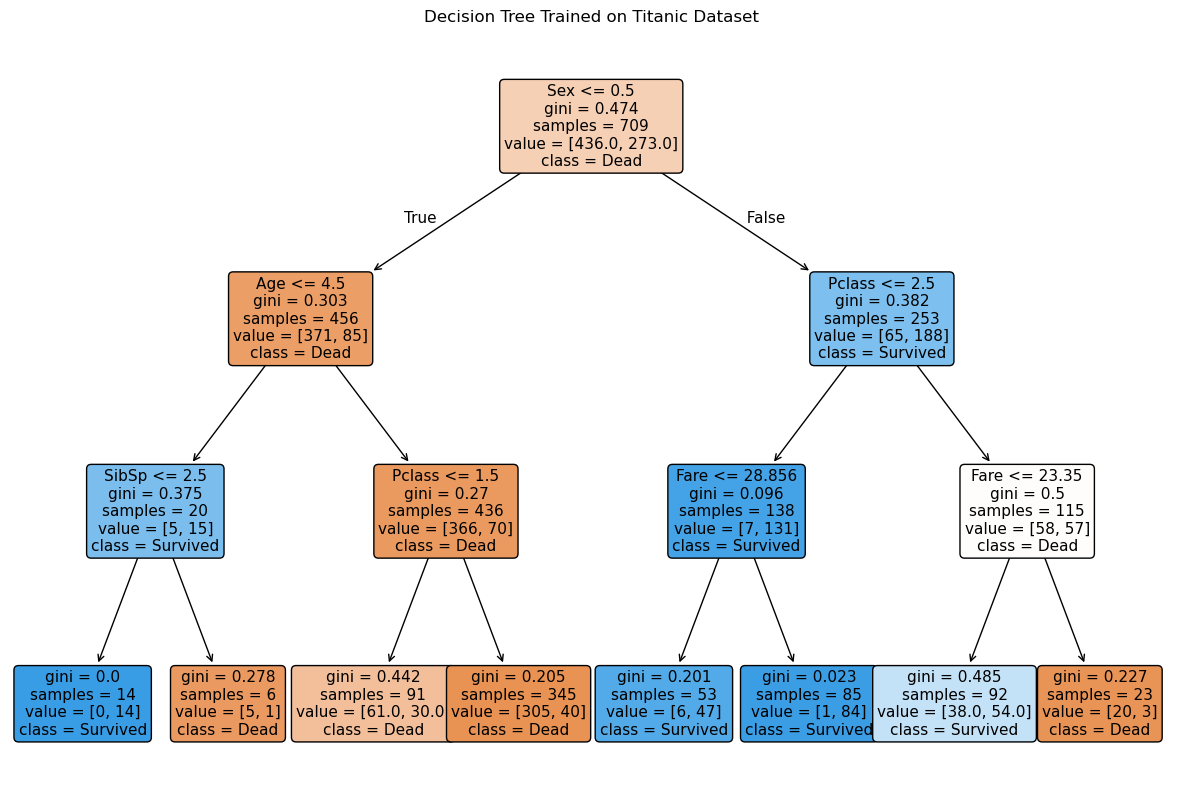

In [59]:
plt.figure(figsize=(15,10))

plot_tree(
    tree_model,
    feature_names=features,
    class_names=["Dead", "Survived"],
    filled=True,
    rounded=True,
    fontsize=11
)

plt.title('Decision Tree Trained on Titanic Dataset')
plt.show()

In [60]:
tree_predictions = tree_model.predict(x_test)
tree_accuracy = accuracy_score(
y_test,
tree_predictions
)
print("Decision Tree Accuracy:", tree_accuracy)

Decision Tree Accuracy: 0.8033707865168539


In [61]:
print(classification_report(y_test, tree_predictions))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       109
           1       0.79      0.67      0.72        69

    accuracy                           0.80       178
   macro avg       0.80      0.78      0.79       178
weighted avg       0.80      0.80      0.80       178



In [62]:
#Train Random Forest

forest_model = RandomForestClassifier(
    random_state = 42,
    n_estimators = 100,
max_depth = 3
)

forest_model.fit(x_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [63]:
forest_predictions = forest_model.predict(x_test)
forest_accuracy = accuracy_score(
y_test,
forest_predictions
)
print("Random Forest Accuracy:", forest_accuracy)

Random Forest Accuracy: 0.8089887640449438


In [64]:
print(classification_report(y_test, forest_predictions))

              precision    recall  f1-score   support

           0       0.82      0.89      0.85       109
           1       0.80      0.68      0.73        69

    accuracy                           0.81       178
   macro avg       0.81      0.79      0.79       178
weighted avg       0.81      0.81      0.81       178



In [67]:
import joblib

# joblib.dump(logistic_model, "logistic_model.joblib")
# joblib.dump(tree_model, "tree_model.joblib")
joblib.dump(forest_model, "forest_model.joblib")

['forest_model.joblib']

In [32]:
# Let's compare out Models

results = pd.DataFrame({
"Model": [
"Logistic Regression",
"Decision Tree",
"Random Forest"
],
"Accuracy": [
logistic_accuracy,
tree_accuracy,
forest_accuracy
    ]
})
results

,Model,Accuracy
0,Logistic Regression,0.634831
1,Decision Tree,0.803371
2,Random Forest,0.808989


In [33]:
results['Accuracy'] = results['Accuracy']*100
results['Accuracy'] = results['Accuracy'].round(2)

In [34]:
results.sort_values(
by="Accuracy",
ascending=False
)

,Model,Accuracy
2,Random Forest,80.90
1,Decision Tree,80.34
0,Logistic Regression,63.48


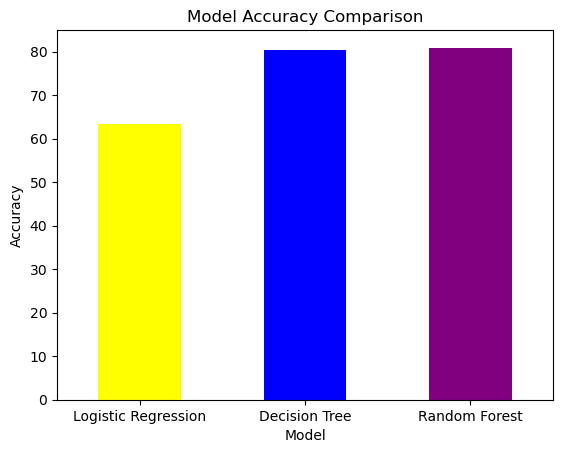

In [35]:
colors= ['Yellow', 'Blue', 'Purple']
results.plot(
x="Model",
y="Accuracy",
kind="bar",
color=colors,
legend=False
)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.show()

In [35]:
#Train 2nd Random Forest

forest_model_2 = RandomForestClassifier(
    random_state = 42,
    n_estimators = 70,
    max_depth = 7
    
)

forest_model_2.fit(x_train, y_train)

,n_estimators,70
,criterion,'gini'
,max_depth,7
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [36]:
forest_predictions_2 = forest_model_2.predict(x_test)
forest_accuracy_2 = accuracy_score(
y_test,
forest_predictions_2
)
print("Random Forest Accuracy:", forest_accuracy_2)

Random Forest Accuracy: 0.797752808988764


**Tuning & Optimization (hyperparameters)**

In [37]:
# Tune the Decision Tree
tree_params = {
"max_depth": [2, 3, 4, 5, 6, 8, 10],
}
tree_grid = GridSearchCV(
DecisionTreeClassifier(random_state=42),
tree_params,
cv=5,
scoring="accuracy"
)
tree_grid.fit(x_train, y_train)

,estimator,DecisionTreeC...ndom_state=42)
,param_grid,"{'max_depth': [2, 3, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [38]:
print("Best Parameters:")
print(tree_grid.best_params_)
print("Best Cross-Validation Accuracy:")
print(tree_grid.best_score_)

Best Parameters:
{'max_depth': 4}
Best Cross-Validation Accuracy:
0.818060133852762


In [39]:
# Evaluate the Tuned Decision Tree
best_tree = tree_grid.best_estimator_
tuned_tree_predictions = best_tree.predict(x_test)
tuned_tree_accuracy = accuracy_score(
y_test,
tuned_tree_predictions
)
print("Tuned Decision Tree Accuracy:", tuned_tree_accuracy)

Tuned Decision Tree Accuracy: 0.8033707865168539


In [ ]:
# Tune the Random Forest
forest_params = {
"n_estimators": [50, 100, 200],
"max_depth": [3, 5, 7, 10]
}

forest_grid = GridSearchCV(
RandomForestClassifier(random_state=42),
forest_params,
cv=5,
scoring="accuracy"
)

forest_grid.fit(x_train, y_train)

In [ ]:
print("Best Parameters:")
print(forest_grid.best_params_)
print("\nBest Cross-Validation Accuracy:")
print(forest_grid.best_score_)

In [42]:
best_forest = forest_grid.best_estimator_

tuned_forest_predictions = best_forest.predict(x_test)

tuned_forest_accuracy = accuracy_score(
y_test,
tuned_forest_predictions
)

print(
"Tuned Random Forest Accuracy:",
tuned_forest_accuracy
)

Tuned Random Forest Accuracy: 0.797752808988764


In [43]:
print(classification_report(y_test, tuned_forest_predictions))

              precision    recall  f1-score   support

           0       0.81      0.88      0.84       109
           1       0.78      0.67      0.72        69

    accuracy                           0.80       178
   macro avg       0.79      0.77      0.78       178
weighted avg       0.80      0.80      0.79       178



In [44]:
# Compare Before and After Tuning

final_results = pd.DataFrame({
"Model": [
"Logistic Regression",
"Decision Tree - Before Tuning",
"Decision Tree - After Tuning",
"Random Forest - Before Tuning",
"Random Forest - After Tuning"
],
"Accuracy": [
    logistic_accuracy,
    tree_accuracy,
    tuned_tree_accuracy,
    forest_accuracy,
    tuned_forest_accuracy
]
})

final_results

,Model,Accuracy
0,Logistic Regression,0.634831
1,Decision Tree - Before Tuning,0.803371
2,Decision Tree - After Tuning,0.803371
3,Random Forest - Before Tuning,0.808989
4,Random Forest - After Tuning,0.797753


In [45]:
def predict_survival(name, Pclass, Sex, Age, SibSp, PaCh, Fare):
    """
    Predict survival using our model
    """
    input_data = pd.DataFrame({
    'Pclass': [Pclass],
    'Sex': [Sex],
    'Age': [Age],
    'SibSp': [SibSp],
    'PaCh': [PaCh],
    'Fare': [Fare]
    })
    
    prediction = best_forest.predict(input_data)[0]
    probabilities = best_forest.predict_proba(input_data)[0] # to explain
    if prediction == 0:
        result = f'Wooo 😮 {name.title()}, you Died 😢 '
    else:
        result = f'Cheers 🥂 {name.title()}, you Survived 😁 '
    return result, probabilities

In [46]:
print(predict_survival('Tomi', Pclass=3, Sex=1, Age=25.0, SibSp=0, PaCh=0, Fare=100))

('Cheers 🥂 Tomi, you Survived 😁 ', array([0.37671003, 0.62328997]))


In [45]:
svm_model = SVC()
svm_model.fit(x_train_scaled, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [46]:
svm_predictions = svm_model.predict(x_test_scaled)

svm_accuracy = accuracy_score(
    y_test,
    svm_predictions
)

print('SVM Accuracy Score:', svm_accuracy)

SVM Accuracy Score: 0.8089887640449438


In [47]:
print(classification_report(y_test, svm_predictions))

              precision    recall  f1-score   support

           0       0.82      0.89      0.85       109
           1       0.80      0.68      0.73        69

    accuracy                           0.81       178
   macro avg       0.81      0.79      0.79       178
weighted avg       0.81      0.81      0.81       178



**Understanding Confusion Matrix**

A confusion matrix is a simple table used to score a machine learning model's
performance on a yes/no guessing task. It shows exactly where the model got
things right and where it got "confused/wrong". The confusion matrix helps us
understand not just how many predictions were correct, but also what kinds of
mistakes the model made.

**In our Titanic prediction model, the goal is to predict whether a passenger
Survived (Positive/Yes) or Died (Negative/No)**

A confusion matrix splits the model's guesses into four distinct quadrants:
- True/Actual Positive (TP)
- True/Actual Negative (TN)
- False Positive (FP)
- False Negative (FN)

For this project: Positive = survived, Negative = did not survive
- 97 (True Negatives - TN): The model predicted these passengers Died, and they
actually died. The model was correct.
- 46 (True Positives - TP): The model predicted these passengers Survived, and
they actually survived. The model was correct.
- 12 (False Positives - FP): The model predicted these passengers Survived, but
they actually died. This is a false alarm.
- 23 (False Negatives - FN): The model predicted these passengers Died, but they
actually survived. The model completely missed them

Easy Rule:

- The diagonal numbers from top-left to bottom-right (97 and 46) are the correct
guesses.
- The other numbers (12 and 23) are the mistakes.

**What does support mean?**

- The support is simply the number of actual examples belonging to that class in
the test set. 109 + 69 = 178

In [48]:
forest_cm = confusion_matrix(
y_test,
tuned_forest_predictions
)
print(forest_cm)

[[96 13]
 [23 46]]


In [49]:
print(classification_report(y_test, tuned_forest_predictions))

              precision    recall  f1-score   support

           0       0.81      0.88      0.84       109
           1       0.78      0.67      0.72        69

    accuracy                           0.80       178
   macro avg       0.79      0.77      0.78       178
weighted avg       0.80      0.80      0.79       178



In [50]:
len(y_test)

178

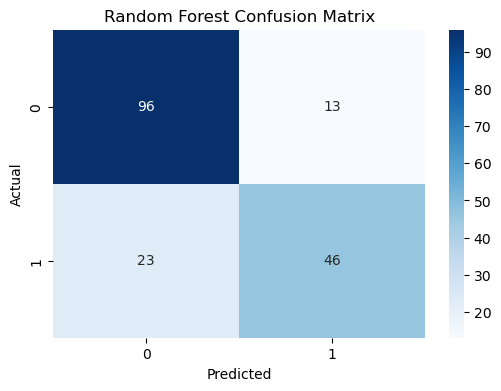

In [51]:
import seaborn as sns
# Ensure the title matches your actual variable (e.g., forest_cm)
plt.figure(figsize=(6, 4))
sns.heatmap(forest_cm, annot=True, fmt="d", cmap="Blues", cbar=True)
# Add labels and title
plt.title("Random Forest Confusion Matrix") # Updated to match variable
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**28/09/2026   Regression**

**California Housing Price Prediction**

In [54]:
from sklearn.datasets import fetch_california_housing
# Load dataset
housing = fetch_california_housing()
x = pd.DataFrame(housing.data, columns=housing.feature_names)
y = housing.target # Median house value in $100,000s
x.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [55]:
y

array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,))

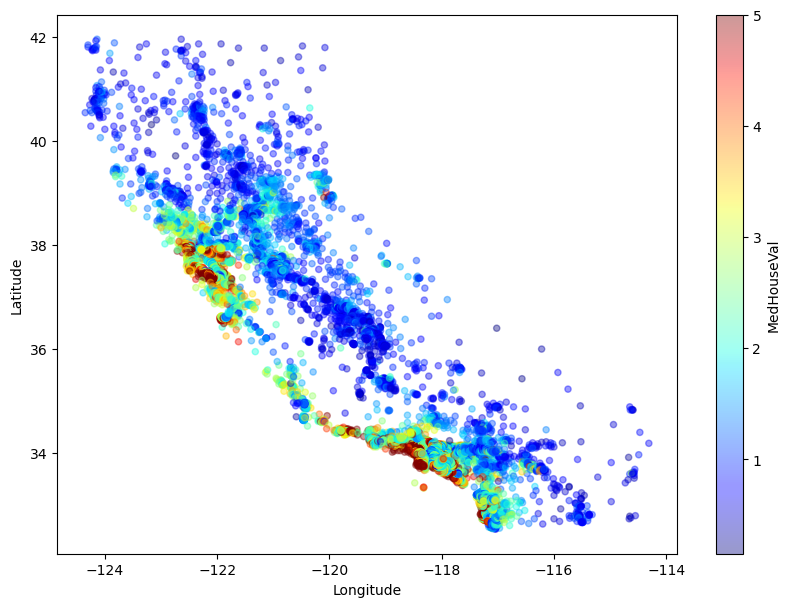

In [56]:
#Plot housing locations colored by median house value
california = fetch_california_housing()
housing_df = pd.DataFrame(california.data, columns=california.feature_names)
housing_df['MedHouseVal'] = california.target
housing_df.plot(
kind="scatter",
x="Longitude",
y="Latitude",
alpha=0.4,
c="MedHouseVal",
cmap=plt.get_cmap("jet"),
colorbar=True,
figsize=(10, 7),
)
plt.show()

In [58]:
#Split and Preprocess Data

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split into train/test
x_train, x_test, y_train, y_test = train_test_split(
x, y, test_size=0.2, random_state=42
)
# Scale features
# StandardScaler scales features to have mean 0 and std 1
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [60]:
# Training a Regrression Model, let's use Linear Regression:

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [61]:
# Evaluate the Model
from sklearn.metrics import mean_squared_error
y_pred = model.predict(x_test_scaled)

mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
# (lower is better, 0 is perfect)

Mean Squared Error: 0.56


In [62]:
# The coefficient of determination or R^2

model.score(x_test_scaled, y_test)
# higher is better, 1 is perfect

0.5757877060324512

**1. R-squared (R^2): This number (from 0 to 1) shows what fraction of the variation in your target data is explained by your model.**


An R^2 of 0.80 means your model explains 80% pattern in the data


**2. Mean Squared Error (MSE): measures the average squared difference between predicted and actual values:**

Always >= 0. Lower MSE = better model. 


**3. Root Mean Squared Error (RMSE):**


This measures prediction error just like MAE, but it squares the errors first. This gives more weight to large mistakes, making it helpful if big errors are dangerous. 


**4. Mean Absolute Error (MAE):**


This is the average absolute distance between your predictions and the actual values. If you are predicting house prices and your MAE is 10,000, your guesses are off by 10,000 on average in real units.


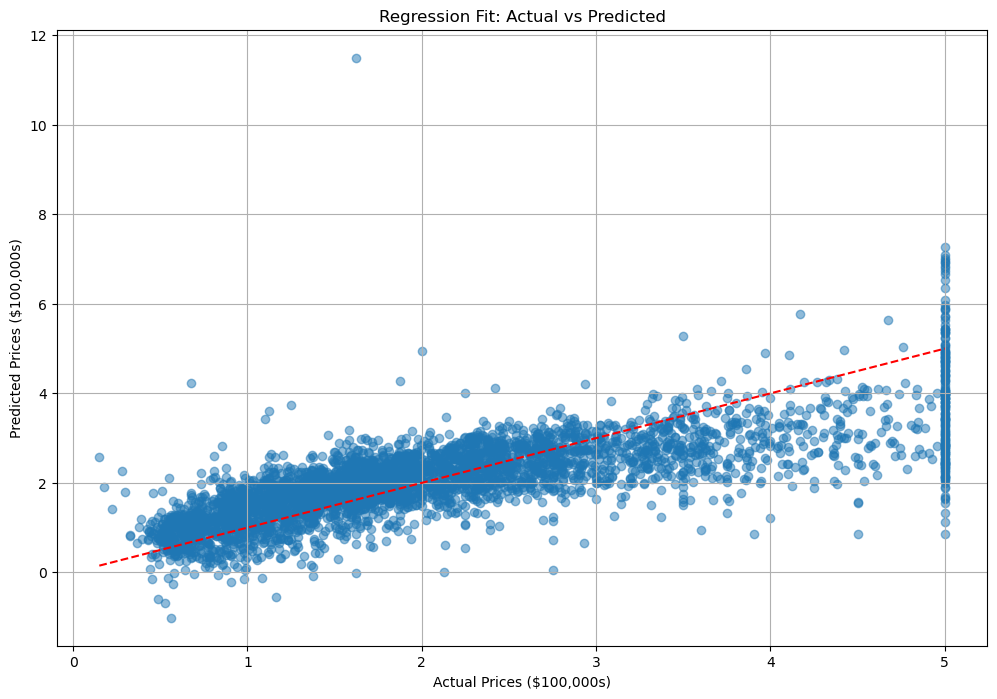

In [63]:
#Lets visualize: plot Actual vs Predicted (Regression Fit)

import matplotlib.pyplot as plt 

# import seaborn as sns 
plt.figure(figsize=(12, 8)) 
plt.scatter(x=y_test, y=y_pred, alpha=.5) 
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--')
plt.xlabel("Actual Prices ($100,000s)") 
plt.ylabel("Predicted Prices ($100,000s)") 
plt.title("Regression Fit: Actual vs Predicted") 
plt.grid(True) 
plt.show()

# the regression fit compares actual vs. predicted values, with the red dash lin representing a perfect fit
# If points closely follow the line, predictions are accurate, but if a pattern (e.g a curve) appears
# The red line is the ideal line — the closer your points are to this, the better


In [64]:
#Using the first model, result should be the same

def predict_house_price2(MedInc, HouseAge, AveRooms, AveBedrms,  Population, AveOccup, Latitude, Longitude): 
    
 # Prepare input as a 2D array (one row, 8 features)  
    sample = [[MedInc, HouseAge, AveRooms, AveBedrms, 
     Population, AveOccup, Latitude, Longitude]]  
    sample = scaler.transform(sample) 
    predicted_price = model.predict(sample)[0]
    bla = model.predict(sample)
    return f"Estimated House Price: ${predicted_price * 100000:,.2f}" 
 

In [65]:
predict_house_price2(MedInc=8.3, HouseAge=41.0, AveRooms=6.0, AveBedrms=1 , Population=980, AveOccup=2.5, Latitude=37.5, Longitude=-122.3)

C:\Users\adeol\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


'Estimated House Price: $443,209.67'

In [66]:
predict_house_price2(MedInc=8.3, HouseAge=45.0, AveRooms=6.0, AveBedrms=1, Population=780, AveOccup=2.5, Latitude=37.5, Longitude=-122.3)

C:\Users\adeol\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


'Estimated House Price: $447,139.97'

**29/09/2026 - PIPELINE**

In [68]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
('scaler', StandardScaler()),
('model', LinearRegression())
])

pipeline.fit(x_train, y_train)

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None


In [69]:
# Evaluate the Model

y_pred = pipeline.predict(x_test)
mse = mean_squared_error(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")

Mean Squared Error: 0.56


In [70]:
pipeline.score(x_test, y_test)

0.5757877060324512

In [71]:
x_test.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude'],
      dtype='object')

In [89]:
# Let's create a Prediction Function that accepts 8 input values
# and returns the predicted house price in dollars.

def predict_house_price(MedInc, HouseAge, AveRooms, AveBedrms,
                        Population, AveOccup, Latitude, Longitude):
    
    # Prepare input as a 2D array (one row, 8 features)
    sample = pd.DataFrame({
        'MedInc' : [MedInc],
        'HouseAge' : [HouseAge],
        'AveRooms' : [AveRooms],
        'AveBedrms' : [AveBedrms],
        'Population' : [Population],
        'AveOccup' : [AveOccup],
        'Latitude' : [Latitude],
        'Longitude' : [Longitude]
        
    })
    predicted_price = pipeline.predict(sample)[0]
    return f"Estimated House Price: ${predicted_price * 100_000:,.2f}"

In [90]:
predict_house_price(MedInc=8.3, HouseAge=41.0, AveRooms=6.0, AveBedrms=1.0, Population=980, AveOccup=2.5, Latitude=37.5, Longitude=-122.3)

'Estimated House Price: $443,209.67'

**Standard Scaler**

StandardScaler scales the data to have a mean of 0 and a standard deviation of 1. This is also known as z-scoring or whitening. StandardScaler is useful when the data has a large range of values, and you want to reduce the effect of outliers. It's also useful when you're working with algorithms that are sensitive to the scale of the data.

**Classification (Multi-Class): Iris Dataset**

**Let's predict the species of an iris flower based on
its measurements like:**

**sepal length, sepal width, petal length, petal width**

In [2]:
# Load the Dataset

from sklearn.datasets import load_iris

iris = load_iris()
X, y = iris.data, iris.target

print(iris.feature_names)
print(iris.target_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']


In [3]:
# Split the Data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=.2, random_state=1
)

In [4]:
X_train[:10]

array([[6.1, 3. , 4.6, 1.4],
       [7.7, 3. , 6.1, 2.3],
       [5.6, 2.5, 3.9, 1.1],
       [6.4, 2.8, 5.6, 2.1],
       [5.8, 2.8, 5.1, 2.4],
       [5.3, 3.7, 1.5, 0.2],
       [5.5, 2.3, 4. , 1.3],
       [5.2, 3.4, 1.4, 0.2],
       [6.5, 2.8, 4.6, 1.5],
       [6.7, 2.5, 5.8, 1.8]])

In [5]:
y_train[:10]

array([1, 2, 1, 2, 2, 0, 1, 0, 1, 2])

In [6]:
for i, value in enumerate(iris.target_names):
    print(i, value)

0 setosa
1 versicolor
2 virginica


In [7]:
# Train a Classifier. Let's use a Logistic Regression

from sklearn.linear_model import LogisticRegression
clf_model = LogisticRegression(max_iter=200)
clf_model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


In [8]:
# Evaluate the Classifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = clf_model.predict(X_test)

In [9]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9666666666666667


In [10]:
print(y_pred)
print(y_test)

[0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 2 0 2 1 0 0 1 2]
[0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 1 0 2 1 0 0 1 2]


In [11]:
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      0.92      0.96        13
           2       0.86      1.00      0.92         6

    accuracy                           0.97        30
   macro avg       0.95      0.97      0.96        30
weighted avg       0.97      0.97      0.97        30



In [12]:
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))


Confusion Matrix:
 [[11  0  0]
 [ 0 12  1]
 [ 0  0  6]]


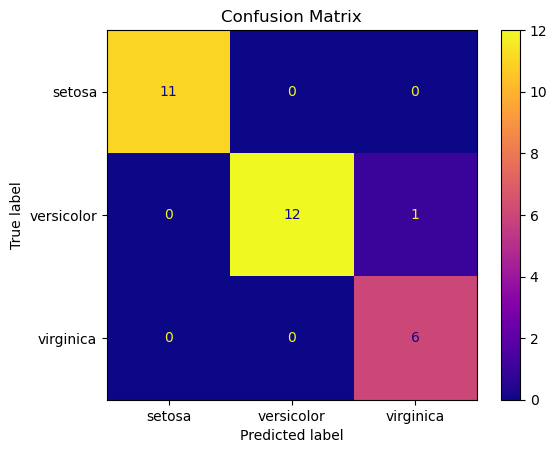

In [14]:
import matplotlib.pyplot as plt

cm_display = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=iris.target_names)
cm_display.plot(cmap=plt.cm.plasma)
plt.title('Confusion Matrix')
# plt.colorbar()
plt.show()

**Creating a Prediction Function**

**Let build a function that:**

- Accepts 4 flower measurements
- Predicts the species name

In [110]:
def predict_flower(sepal_length, sepal_width, petal_length, petal_width):
    sample = [[sepal_length, sepal_width, petal_length, petal_width]]
    # Predict
    pred = clf_model.predict(sample)[0]
    species = iris.target_names
    prediction = f'The specie of flower is {species[pred]}'
    return prediction

In [111]:
print(predict_flower(5.1, 3.5, 1.4, 0.2))

The specie of flower is setosa


In [112]:
print(predict_flower(6.0, 3.0, 4.8, 1.8))

The specie of flower is virginica


In [113]:
clf_model.predict([[5.1, 3.5, 1.4, 0.2]])

array([0])

****Data Preprocessing and Feature
Engineering****

**Handling Missing Values**

**Data preprocessing and feature engineering can significantly improve your
model’s performance.
Missing values can break training algorithms or introduce bias. You should
either fill (impute) or remove them. Types of imputer**

SimpleImputer: Replaces missing values with:
- mean, median, or most_frequent
- A constant value

In [120]:
df = pd.DataFrame({
'name': ['Tomi', 'Funmi', 'Arafat', 'Halimat', 'Abiola'],
'age': [25, 30, np.nan, 35, 40],
'income': [50000, 60000, 55000, np.nan, 65000]
})
df

,name,age,income
0,Tomi,25.0,50000.0
1,Funmi,30.0,60000.0
2,Arafat,NaN,55000.0
3,Halimat,35.0,NaN
4,Abiola,40.0,65000.0


In [121]:
from sklearn.impute import SimpleImputer

# Impute with column mean, check docs for others
imputer = SimpleImputer(strategy='mean')
df['age'] = imputer.fit_transform(df['age'].to_numpy().reshape(-1,1))

# the reshape methode reshapes your array with 1 column and as many rows as necessary to
# accommodate the data. This operation will result in a 2D array with a shape (n-1),
# where n is the number of elements in your original array 

df

,name,age,income
0,Tomi,25.0,50000.0
1,Funmi,30.0,60000.0
2,Arafat,32.5,55000.0
3,Halimat,35.0,NaN
4,Abiola,40.0,65000.0


In [122]:
df = pd.DataFrame({
'age': [25, 30, np.nan, 35, 40],
'income': [50000, 60000, 55000, np.nan, 65000]
})

df

,age,income
0,25.0,50000.0
1,30.0,60000.0
2,NaN,55000.0
3,35.0,NaN
4,40.0,65000.0


In [123]:
imputer = SimpleImputer(strategy='median')
clean_df = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
clean_df

,age,income
0,25.0,50000.0
1,30.0,60000.0
2,32.5,55000.0
3,35.0,57500.0
4,40.0,65000.0


In [124]:
df[['age', 'income']]

,age,income
0,25.0,50000.0
1,30.0,60000.0
2,NaN,55000.0
3,35.0,NaN
4,40.0,65000.0


**KNNImputer: Uses k-nearest neighbors to impute missing
values.**

**Imputation for completing missing values using k-Nearest Neighbors. Each
sample's missing values are imputed using the mean value from n_neighbors
nearest neighbors. It works by finding the k-nearest neighbors for the data
points with missing values and take a mean/average of them**

In [125]:
df = pd.DataFrame({
'age': [25, 30, np.nan, 35, 40, 10, 25],
'income': [50000, 60000, 55000, np.nan, 65000, 20000, 25000]
})
df

,age,income
0,25.0,50000.0
1,30.0,60000.0
2,NaN,55000.0
3,35.0,NaN
4,40.0,65000.0
5,10.0,20000.0
6,25.0,25000.0


In [128]:
from sklearn.impute import KNNImputer

# distances are calculated using a modified Euclidean distance metric (nan_euclidean_distances)

imputer = KNNImputer(n_neighbors=2)
clean_df = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

clean_df

# for age: mean of index 0 and 1
# for income: mean of index 1 and 4

,age,income
0,25.0,50000.0
1,30.0,60000.0
2,27.5,55000.0
3,35.0,62500.0
4,40.0,65000.0
5,10.0,20000.0
6,25.0,25000.0


**Feature Scaling**

Algorithms like SVM, KNN, and Logistic Regression are sensitive to feature
scales. It means that the performance of these algorithms can be significantly
impacted if the input features have different ranges or magnitudes.
StandardScaler: Scales data to zero mean and unit variance (mean of 0 and a
standard deviation of 1). (Standard deviation is the square root of the variance).

In [129]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_scaled = scaler.fit_transform(clean_df)

x_scaled

array([[-0.2852987 ,  0.10540926],
       [ 0.2852987 ,  0.69570109],
       [ 0.        ,  0.40055517],
       [ 0.8558961 ,  0.84327404],
       [ 1.42649351,  0.990847  ],
       [-1.99709091, -1.66546623],
       [-0.2852987 , -1.37032032]])

**MinMaxScaler**

**Scales data to a 0–1 range (or any custom range). Useful for neural networks.**

In [133]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
x_scaled = scaler.fit_transform(clean_df)
x_scaled

array([[0.5       , 0.66666667],
       [0.66666667, 0.88888889],
       [0.58333333, 0.77777778],
       [0.83333333, 0.94444444],
       [1.        , 1.        ],
       [0.        , 0.        ],
       [0.5       , 0.11111111]])

**MaxAbsScaler**

**The MaxAbsScaler works by finding the maximum absolute value and dividing
each value by it. This ensures that the maximum absolute value is 1. This
estimator scales and translates each feature individually such that the maximal
absolute value of each feature in the training set will be 1.0. It does not
shift/center the data, and thus does not destroy any sparsity**

In [134]:
clean_df

,age,income
0,25.0,50000.0
1,30.0,60000.0
2,27.5,55000.0
3,35.0,62500.0
4,40.0,65000.0
5,10.0,20000.0
6,25.0,25000.0


In [135]:
from sklearn.preprocessing import MaxAbsScaler
scaler = MaxAbsScaler()
X_scaled = scaler.fit_transform(clean_df)
X_scaled

array([[0.625     , 0.76923077],
       [0.75      , 0.92307692],
       [0.6875    , 0.84615385],
       [0.875     , 0.96153846],
       [1.        , 1.        ],
       [0.25      , 0.30769231],
       [0.625     , 0.38461538]])

**30/09/2026 - ENCODING**

**Encoding Categorical Variables**

**Encoding categorical variables means converting them into a numerical format
that machine learning models can understand. This is necessary because most
algorithms require numerical input. In simple terms, most ML algorithms can’t
handle text labels. You must convert them to numeric form.**

In [12]:
#Let use Titanic data

df = pd.read_csv('data/titanic.csv')

df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,PaCh,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [13]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False, dtype=int) # set sparse or sparse_output=False for a dense array
# By setting this flag, you choose to represent your data in a sparse formatting
# this tells scikit-learn to return a standard, full NumPy array (a dense matrix)
# instead of a memory-saving compressed data structure
# This saves a lot of memory when you have an array where most of the elements are zero

encoded = encoder.fit_transform(df[['Sex']])

encoded_df= pd.DataFrame(encoded, columns=encoder.get_feature_names_out())

encoded_df.head()

,Sex_female,Sex_male
0,0,1
1,1,0
2,1,0
3,1,0
4,0,1


In [14]:
df_final = pd.concat([df.drop('Sex', axis=1), encoded_df], axis=1)
df_final

,Survived,Pclass,Name,Age,SibSp,PaCh,Fare,Sex_female,Sex_male
0,0,3,Mr. Owen Harris Braund,22.0,1,0,7.2500,0,1
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,38.0,1,0,71.2833,1,0
2,1,3,Miss. Laina Heikkinen,26.0,0,0,7.9250,1,0
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,35.0,1,0,53.1000,1,0
4,0,3,Mr. William Henry Allen,35.0,0,0,8.0500,0,1
...,...,...,...,...,...,...,...,...,...
882,0,2,Rev. Juozas Montvila,27.0,0,0,13.0000,0,1
883,1,1,Miss. Margaret Edith Graham,19.0,0,0,30.0000,1,0
884,0,3,Miss. Catherine Helen Johnston,7.0,1,2,23.4500,1,0
885,1,1,Mr. Karl Howell Behr,26.0,0,0,30.0000,0,1


In [15]:
from sklearn.preprocessing import OneHotEncoder

data = pd.DataFrame({'color': ['red', 'green', 'blue', 'green']})
data

,color
0,red
1,green
2,blue
3,green


In [16]:
encoder = OneHotEncoder(sparse_output=False, dtype=int)
encoded = encoder.fit_transform(data[['color']])
pd.DataFrame(encoded, columns=encoder.get_feature_names_out())

,color_blue,color_green,color_red
0,0,0,1
1,0,1,0
2,1,0,0
3,0,1,0


**OrdinalEncoder -**

Converts categories to integers based on order (if any).

In [42]:
data = pd.DataFrame({'education': ['highschool', 'bachelor', 'master', 'phd']})
data

,education
0,highschool
1,bachelor
2,master
3,phd


In [43]:
data = {'name': ['Abiola', 'Tomi', 'Zainab', 'Rahmat', 'Hannah', 'Rachael'],
'education': ['highschool', 'bachelor', 'master', 'phd', 'bachelor', 'master']}
df = pd.DataFrame(data)

df

,name,education
0,Abiola,highschool
1,Tomi,bachelor
2,Zainab,master
3,Rahmat,phd
4,Hannah,bachelor
5,Rachael,master


In [25]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(categories=[['highschool', 'bachelor', 'master', 'phd']], dtype=int)

# Please, note the difference
# If a specific order is desired
# encoder = OrdinalEncoder(categories=[['highschool', 'bachelor', 'master', 'phd']])
# If no specific order is provided, it will be determined by the order of
# encoder = OrdinalEncoder()

In [26]:
df['education_encoded'] = encoder.fit_transform(df[['education']])
df

,name,education,education_encoded
0,Abiola,highschool,0
1,Tomi,bachelor,1
2,Zainab,master,2
3,Rahmat,phd,3
4,Hannah,bachelor,1
5,Rachael,master,2


**ColumnTransformer & Custom Pipelines**

Column Transformer is a sciket-learn class used to create and apply separate
transformers for numerical and categorical data. It help us to fit multiple
transformations to multiple columns with a single fit() or fit_transform(). This is
particularly useful when you have a mix of numerical and categorical data that
require different preprocessing steps.

In [27]:
df = pd.DataFrame({
'name': ['Funmi', 'Esther', 'Dan', 'Hannah', 'Ben'],
'age': [25, 30, 35, 40, 39],
'income': [50000, 60000, 65000, 70000, 50000],
'gender': ['female', 'female', 'male', 'female', 'male'],
'label': [0, 0, 1, 0, 1]

})

df

,name,age,income,gender,label
0,Funmi,25,50000,female,0
1,Esther,30,60000,female,0
2,Dan,35,65000,male,1
3,Hannah,40,70000,female,0
4,Ben,39,50000,male,1


In [34]:
#you seperate/pick the features you need

X = df[['age', 'income', 'gender']]
y = df[['label']]

In [35]:
#Define column types

num_features = ['age', 'income']
cat_features = ['gender']

In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# the name "num and cat" doesnt have to be, yoi can use any name you want

preprocessor = ColumnTransformer(transformers=[
('num', StandardScaler(), num_features),
('cat', OneHotEncoder(), cat_features)
])

In [37]:
# just to see what the data looks like
new = preprocessor.fit_transform(df)
new

array([[-1.56150157, -1.125     ,  1.        ,  0.        ],
       [-0.67428477,  0.125     ,  1.        ,  0.        ],
       [ 0.21293203,  0.75      ,  0.        ,  1.        ],
       [ 1.10014883,  1.375     ,  1.        ,  0.        ],
       [ 0.92270547, -1.125     ,  0.        ,  1.        ]])

In [38]:
pipeline = Pipeline(steps=[
('preprocessing', preprocessor),
('classifier', LogisticRegression())
])

In [44]:
pipeline.fit(X, y)

C:\Users\adeol\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


06/10/2026

**Let's build a simple classification model with the
Titanic Dataset**

In [5]:
#import file
titanic_data = pd.read_csv('data/titanic.csv')
titanic_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,PaCh,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [6]:
# first, we'll convert our Sex to categorical
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False, dtype=int)
encoded_sex = encoder.fit_transform(titanic_data[['Sex']])
encoded_sex = pd.DataFrame(encoded_sex, columns=encoder.get_feature_names_out())

encoded_sex.head()

,Sex_female,Sex_male
0,0,1
1,1,0
2,1,0
3,1,0
4,0,1


In [7]:
clean_data = pd.concat([titanic_data.drop('Sex', axis=1), encoded_sex], axis=1)

In [8]:
clean_data.head()

,Survived,Pclass,Name,Age,SibSp,PaCh,Fare,Sex_female,Sex_male
0,0,3,Mr. Owen Harris Braund,22.0,1,0,7.2500,0,1
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,38.0,1,0,71.2833,1,0
2,1,3,Miss. Laina Heikkinen,26.0,0,0,7.9250,1,0
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,35.0,1,0,53.1000,1,0
4,0,3,Mr. William Henry Allen,35.0,0,0,8.0500,0,1


In [9]:
# But there's another way provided by pandas, so pick the one you prefere
#sex = pd.get_dummies(titanic_data['Sex'], drop_first=True, dtype=int)
#sex.head(5)

In [10]:
# Next, let's encode Pclass

encoded_pclass = encoder.fit_transform(titanic_data[['Pclass']])

encoded_pclass = pd.DataFrame(encoded_pclass, columns=encoder.get_feature_names_out())

encoded_pclass.head()

,Pclass_1,Pclass_2,Pclass_3
0,0,0,1
1,1,0,0
2,0,0,1
3,1,0,0
4,0,0,1


In [11]:
# Add it to the main dataset
clean_data = pd.concat([clean_data.drop('Pclass', axis=1), encoded_pclass], axis=1)

clean_data.head()

,Survived,Name,Age,SibSp,PaCh,Fare,Sex_female,Sex_male,Pclass_1,Pclass_2,Pclass_3
0,0,Mr. Owen Harris Braund,22.0,1,0,7.2500,0,1,0,0,1
1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,38.0,1,0,71.2833,1,0,1,0,0
2,1,Miss. Laina Heikkinen,26.0,0,0,7.9250,1,0,0,0,1
3,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,35.0,1,0,53.1000,1,0,1,0,0
4,0,Mr. William Henry Allen,35.0,0,0,8.0500,0,1,0,0,1


In [12]:
# Now, let's drop the name
clean_data.drop(['Name'], axis=1, inplace=True)
clean_data.head()

,Survived,Age,SibSp,PaCh,Fare,Sex_female,Sex_male,Pclass_1,Pclass_2,Pclass_3
0,0,22.0,1,0,7.2500,0,1,0,0,1
1,1,38.0,1,0,71.2833,1,0,1,0,0
2,1,26.0,0,0,7.9250,1,0,0,0,1
3,1,35.0,1,0,53.1000,1,0,1,0,0
4,0,35.0,0,0,8.0500,0,1,0,0,1


In [13]:
X = clean_data.drop('Survived', axis=1)
y = clean_data['Survived']

In [14]:
# next, let's split oue data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

In [15]:
# Let's pick a model
from sklearn.linear_model import LogisticRegression
log_model = LogisticRegression(max_iter=300)

In [16]:
log_model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,300
,multi_class,'deprecated'


In [17]:
# let's test our model
predictions = log_model.predict(X_test)

In [18]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

accuracy_score(y_test, predictions)

0.7715355805243446

In [19]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.82      0.80      0.81       162
           1       0.70      0.72      0.71       105

    accuracy                           0.77       267
   macro avg       0.76      0.76      0.76       267
weighted avg       0.77      0.77      0.77       267



In [20]:
confusion_matrix(y_test, predictions)

array([[130,  32],
       [ 29,  76]])

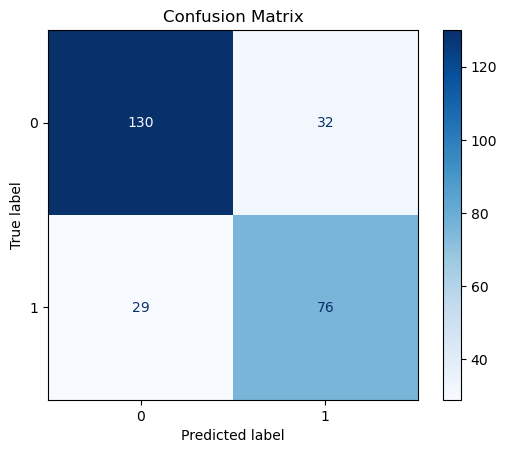

In [21]:
import matplotlib.pyplot as plt

cm_display = ConfusionMatrixDisplay(confusion_matrix(y_test, predictions))
    
cm_display.plot(cmap=plt.cm.Blues)
    
plt.title('Confusion Matrix')
# plt.colorbar()
plt.show()

**Let's train Decision Tree Classifier**

In [22]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
dt_classifier = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_classifier.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


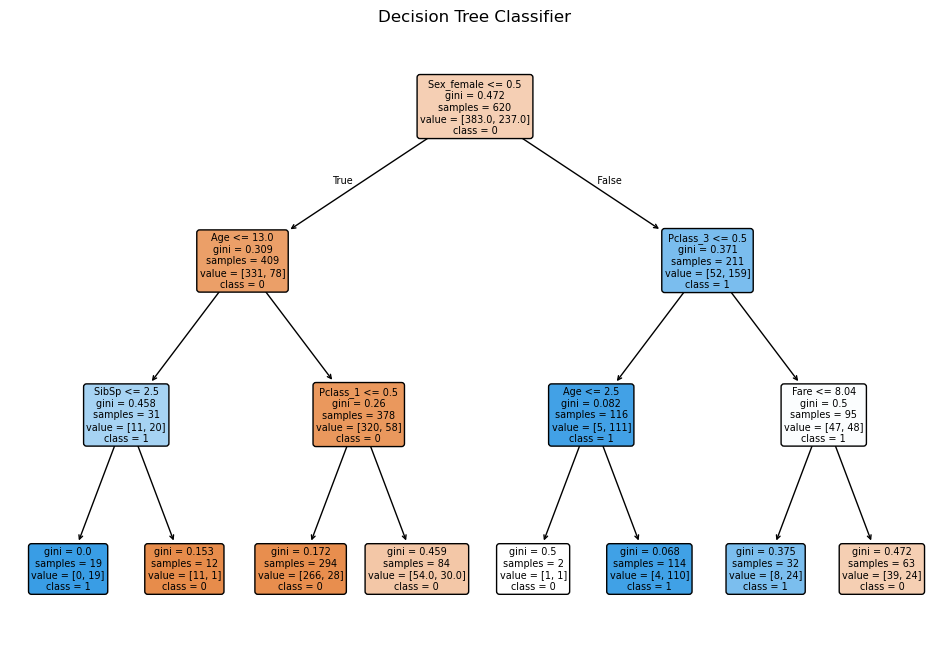

In [23]:
# I'll explain this later
plt.figure(figsize=(12, 8))
plot_tree(dt_classifier, feature_names=X.columns, class_names=['0', '1'], filled=True, rounded=True)
plt.title("Decision Tree Classifier")
plt.show()

In [24]:
# Let's make predictions

y_pred = dt_classifier.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")

Accuracy: 0.80


In [25]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.78      0.93      0.85       162
           1       0.84      0.60      0.70       105

    accuracy                           0.80       267
   macro avg       0.81      0.76      0.77       267
weighted avg       0.80      0.80      0.79       267



In [26]:
confusion_matrix(y_test, y_pred)

array([[150,  12],
       [ 42,  63]])

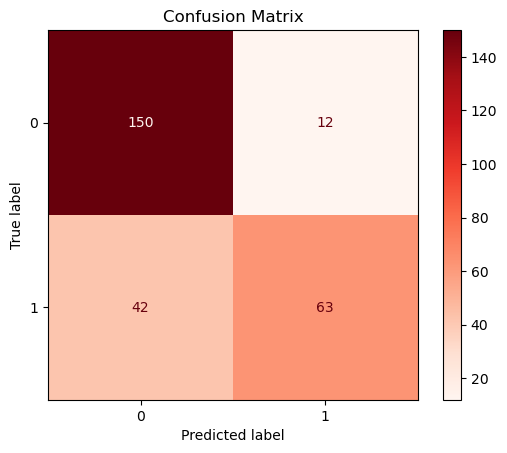

In [27]:
cm_display = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
cm_display.plot(cmap=plt.cm.Reds)
plt.title('Confusion Matrix')
# plt.colorbar()
plt.show()

In [28]:
# Let's use pipeline
X = titanic_data[['Pclass', 'Sex', 'Age', 'SibSp']]
y = titanic_data['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,random_state=1)

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
categorical_features = ['Pclass', 'Sex']
preprocessor = ColumnTransformer(transformers=[
('cat', OneHotEncoder(), categorical_features)
])

lr_pipeline = Pipeline(steps=[
('preprocessor', preprocessor),
('classifier', LogisticRegression(max_iter=300))
])

In [30]:
lr_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [31]:
lr_pred = lr_pipeline.predict(X_test)
lr_accuracy = accuracy_score(y_test, lr_pred)
print(f"Accuracy: {lr_accuracy:.2f}")

Accuracy: 0.78


**Let's build a simple calssification pipeline**

In [32]:
def predict_survival(name, Pclass: int, Sex: str, Age: float, SibSp: int):
    """
    Predict survival using our model
    """
    input_data = pd.DataFrame({
    'Pclass': [Pclass],
    'Sex': [Sex],
    'Age': [Age],
    'SibSp': [SibSp]
 })
    prediction = lr_pipeline.predict(input_data)[0]
    if prediction == 0:
        result = f'Wooo 😮 {name.title()}, you Died 😢 '
    else:
        result = f'Cheers 🥂 {name.title()}, you Survived 😁 '
        
    return result

In [33]:
print(predict_survival('Benjamin', Pclass=3, Sex="male", Age=25.0, SibSp=0))

Wooo 😮 Benjamin, you Died 😢 


In [34]:
print(predict_survival('Carina', Pclass=1, Sex="female", Age=30.0, SibSp=0))

Cheers 🥂 Carina, you Survived 😁 


**12/10/2026**

**FEATURE ENGINEERING**

**Feature engineering is the process of selecting, modifying, and transforming
raw data into features that are more suitable for machine learning models. It
involves creating new features, transforming existing ones, and selecting the
most relevant features to improve model performance and interpretability.
Simply put, the process of creating or selecting the most relevant features to
improve model performance.**

**Why?**

1. Improved Model Accuracy: By creating new, informative features or
transforming existing ones, feature engineering can significantly boost a model's
ability to predict accurately.

2. Reduced Model Complexity: Feature selection, a key part of feature
engineering, helps remove irrelevant or redundant features, leading to simpler
and more efficient models.

3. Enhanced Interpretability: Well-engineered features can make it easier to
understand why a model makes certain predictions, improving the model's transparency and trustworthiness.
  

**Feature Selection**

**This is the process of choosing a subset of relevant features (variables,
predictors) from a larger set of features in a dataset. It's a crucial step in
machine learning, aiming to improve model performance, reduce computational
cost, etc.**

In [35]:
X = clean_data.drop(['Survived', 'Fare'], axis=1)
y = clean_data['Survived']

In [36]:
from sklearn.feature_selection import SelectKBest, chi2
# Apply SelectKBest with chi-squared test (for categorical/boolean features
selector = SelectKBest(score_func=chi2, k=4) # chi2 requires non-negative values
X_selected = selector.fit(X, y)

dfscores = pd.DataFrame(X_selected.scores_)
dfcolumns = pd.DataFrame(X.columns)
featureScores = pd.concat([dfcolumns, dfscores], axis=1)
featureScores.columns = ['Specs', 'Score'] # Naming the dataframe column
featureScores.nlargest(10, 'Score') # Print the top 10 features
# print("Selected feature indices:", selector.get_support(indices=True))

,Specs,Score
3,Sex_female,168.421498
4,Sex_male,92.293805
5,Pclass_1,54.309105
7,Pclass_3,40.994193
0,Age,21.343234
2,PaCh,9.668390
6,Pclass_2,5.913445
1,SibSp,2.829911


In [37]:
X.head()

,Age,SibSp,PaCh,Sex_female,Sex_male,Pclass_1,Pclass_2,Pclass_3
0,22.0,1,0,0,1,0,0,1
1,38.0,1,0,1,0,1,0,0
2,26.0,0,0,1,0,0,0,1
3,35.0,1,0,1,0,1,0,0
4,35.0,0,0,0,1,0,0,1


In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)
model = LogisticRegression()
model.fit(X_train_selected, y_train)
print(f"Accuracy of model with selected features: {model.score(X_test_selected, y_test)}")

Accuracy of model with selected features: 0.7415730337078652


**Model-Based Feature Selection**

**Use feature importances from a model. This uses a machine learning model to
evaluate feature importance and select the most relevant ones. It involves
training a model on the entire dataset and then using model-specific metrics
(like coefficients in linear models or tree-based importances) to determine
which features to keep.**

In [42]:
from sklearn.feature_selection import SelectFromModel
model = LogisticRegression(max_iter=300)
model.fit(X, y)
mdl = SelectFromModel(model)
ix = mdl.get_support()
data3 = pd.DataFrame(mdl.transform(X), columns=X.columns.values[ix])
data3.head()

C:\Users\adeol\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


,Sex_female,Sex_male,Pclass_1,Pclass_3
0,0.0,1.0,0.0,1.0
1,1.0,0.0,1.0,0.0
2,1.0,0.0,0.0,1.0
3,1.0,0.0,1.0,0.0
4,0.0,1.0,0.0,1.0


**Polynomial Features**

**Polynomial features are created by raising existing features to a power
(exponent) and/or creating interaction terms between features. This process is
used in machine learning to capture non-linear relationships in data, which can
improve model performance when linear models are insufficient.**

In [2]:
from sklearn.preprocessing import PolynomialFeatures

# Sample feature matrix
X = np.array([[2, 3]])

# Generate polynomial and interaction features up to degree 2
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

print("Feature names:", poly.get_feature_names_out())
print("Transformed features:\n", X_poly)

Feature names: ['x0' 'x1' 'x0^2' 'x0 x1' 'x1^2']
Transformed features:
 [[2. 3. 4. 6. 9.]]


In [3]:
from sklearn.datasets import fetch_california_housing
california = fetch_california_housing()
df = pd.DataFrame(california.data, columns=california.feature_names)
df['PRICE'] = california.target

In [4]:
# Assuming we want to use features like 'MedInc' (median income), 'HouseA
X = df[['MedInc', 'HouseAge', 'AveRooms']].values
y = df['PRICE'].values

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [6]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train_poly, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [10]:
from sklearn.metrics import mean_squared_error, r2_score
y_pred = model.predict(X_test_poly)
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")

Mean Squared Error: 0.64


In [11]:
r2_score(y_test, y_pred)

0.5100703746746539

**Supervised Learning Models**

**Linear Regression (LinearRegression): Linear regression models the relationship
between one or more independent variables (X) and a continuous target variable (y)
y=β0 + β1x1 + β2x2 +⋯+βnxn**

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import r2_score

data = fetch_california_housing()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)
print("R2 Score:", r2_score(y_test, y_pred))

R2 Score: 0.5757877060324526


**Regularized Linear Models**

Regularization adds a penalty term to prevent overfitting and reduce model
complexity.

**Regularized linear models are a type of linear model that incorporates a penalty
term in the cost function (also known as the loss function, quantifies the error
between the predicted values and the actual values of the data) to prevent
overfitting and improve generalization to new data. This penalty term
discourages overly complex models by shrinking the magnitude of the model's
coefficients**

**NB:Generalization is what happens outside of your training**

**Ridge Regression (L2)**

- Penalizes th sum of squares o coefficients
- Shrinks weight but never zeroes them out


alpha(a) is a hyperparameter that controls the strength of the L1 reularization penalty. It essentially determines how much the model coefficients are shrunk
towards zero.

In [16]:
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=4.0)
ridge.fit(X_train, y_train)
print("Ridge R2:", ridge.score(X_test, y_test))

Ridge R2: 0.5760535888983747


**Lasso Regression (L1)**

- Penalizes sum of absolute values o coefficients

In [15]:
from sklearn.linear_model import Lasso
lasso = Lasso(alpha=0.1)
lasso.fit(X_train, y_train)
print("Lasso R2:", lasso.score(X_test, y_test))

Lasso R2: 0.5318167610318159


**Logistic Regression**

**Logistic regression is a statistical method used for classification problems,
where the goal is to predict the probability of an instance belonging to one
class. Used when the target is categorical (binary or multi-class). Outputs
probabilities, which are thresholded to classify.**

**Let's see an example with Loan dataset**

In [3]:
loan_df= pd.read_csv('data/loan_data.csv')

loan_df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [5]:
loan_df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [6]:
loan_df.duplicated().sum()

np.int64(0)

In [7]:
fill_values = {
'Gender': loan_df['Gender'].mode()[0],
'Married': loan_df['Married'].mode()[0],
'Dependents': loan_df['Dependents'].mode()[0],
'Self_Employed': loan_df['Self_Employed'].mode()[0],
'LoanAmount': loan_df['LoanAmount'].mean(),
'Loan_Amount_Term': loan_df['Loan_Amount_Term'].mean(),
'Credit_History': loan_df['Credit_History'].mode()[0],
}

In [8]:
df_filled = loan_df.fillna(fill_values)
df_filled.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,146.412162,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.000000,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.000000,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.000000,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.000000,360.0,1.0,Urban,Y


In [9]:
df_filled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             614 non-null    object 
 2   Married            614 non-null    object 
 3   Dependents         614 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      614 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         614 non-null    float64
 9   Loan_Amount_Term   614 non-null    float64
 10  Credit_History     614 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [10]:
df_filled.shape

(614, 13)

In [11]:
df_filled.replace({"Loan_Status":{"N":0,"Y":1},
'Married':{'No':0,"Yes":1},
'Gender':{'Male':1,'Female':0},
'Self_Employed':{'No':0,'Yes':1},
'Property_Area':{'Rural':0,"Semiurban":1,'Urban':2},
'Education':{'Graduate':1,'Not Graduate':0}
}, inplace=True)

# You can also do this
# df_filled['Loan_Status'] = df['Loan_Status'].map({'N': 0, 'Y': 1})

C:\Users\adeol\AppData\Local\Temp\ipykernel_8156\11417021.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_filled.replace({"Loan_Status":{"N":0,"Y":1},


In [12]:
df_filled.replace(to_replace="3+", value=4, inplace=True)

In [13]:
df_filled.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,1,0,0,1,0,5849,0.0,146.412162,360.0,1.0,2,1
1,LP001003,1,1,1,1,0,4583,1508.0,128.000000,360.0,1.0,0,0
2,LP001005,1,1,0,1,1,3000,0.0,66.000000,360.0,1.0,2,1
3,LP001006,1,1,0,0,0,2583,2358.0,120.000000,360.0,1.0,2,1
4,LP001008,1,0,0,1,0,6000,0.0,141.000000,360.0,1.0,2,1


**15/10/2026**

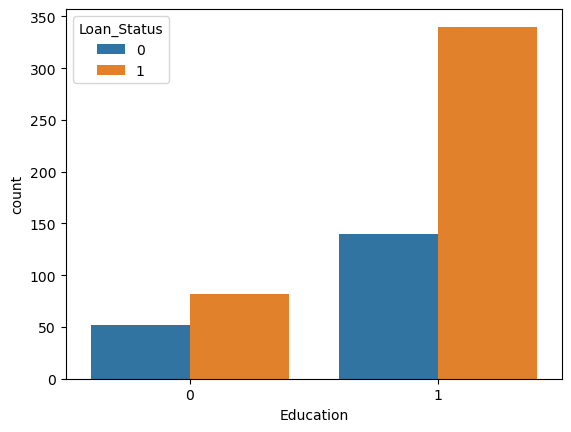

In [14]:
# Let's do some viz
# loas status based on education
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Education', hue='Loan_Status', data=df_filled)
plt.show()

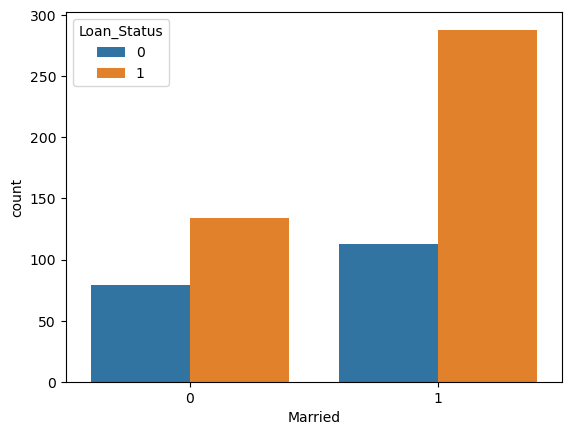

In [15]:
# loas status based on marital status
sns.countplot(x='Married', hue='Loan_Status', data=df_filled)
plt.show()

In [16]:
X = df_filled.drop(columns=['Loan_ID', 'Loan_Status'], axis=1)
y = df_filled['Loan_Status']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.1, random_state=42)

In [18]:
print(X_train.shape, X_test.shape)

(552, 11) (62, 11)


In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

dt_clf = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_clf.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [20]:
y_pred = dt_clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7580645161290323


In [21]:
import joblib
joblib.dump(dt_clf, 'dt_clf.joblib')

['dt_clf.joblib']

In [22]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.33      0.48        21
           1       0.74      0.98      0.84        41

    accuracy                           0.76        62
   macro avg       0.81      0.65      0.66        62
weighted avg       0.79      0.76      0.72        62



In [23]:
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))


Confusion Matrix:
 [[ 7 14]
 [ 1 40]]


In [24]:
from sklearn.feature_selection import SelectKBest, chi2
selector = SelectKBest(score_func=chi2, k=5)
X_selected = selector.fit(X, y)

dfscores = pd.DataFrame(X_selected.scores_)
dfcolumns = pd.DataFrame(X.columns)
featureScores = pd.concat([dfcolumns, dfscores], axis=1)
featureScores.columns = ['Features', 'Score']
featureScores.nlargest(7, 'Score')

# There's a problem here. Our data needs scaling.

,Features,Score
6,CoapplicantIncome,11342.041603
5,ApplicantIncome,93.904964
7,LoanAmount,39.211545
9,Credit_History,26.005877
8,Loan_Amount_Term,3.267315
1,Married,1.782425
3,Education,0.988390


In [45]:
#Let's make some prediction

new_data = pd.DataFrame({
'Gender': [1],
'Married': [0],
'Dependents': [0],
'Education': [1],
'Self_Employed': [0],
'ApplicantIncome': [5000],
'CoapplicantIncome': [0],
'LoanAmount': [1000],
'Loan_Amount_Term': [200],
'Credit_History': [1],
'Property_Area': [2]
})
prediction = dt_clf.predict(new_data)
print(f"Prediction for new data: {'YES' if prediction[0] == 1 else 'NO'}")

Prediction for new data: YES


In [46]:
pred_probability = dt_clf.predict_proba(new_data)
pred_probability

array([[0.16413374, 0.83586626]])

In [47]:
new_data = pd.DataFrame({
'Gender': [1],
'Married': [0],
'Dependents': [0],
'Education': [1],
'Self_Employed': [0],
'ApplicantIncome': [5000],
'CoapplicantIncome': [0],
'LoanAmount': [1000],
'Loan_Amount_Term': [200],
'Credit_History': [0],
'Property_Area': [2]
})
prediction = dt_clf.predict(new_data)
print(f"Prediction for new data: {'YES' if prediction[0] == 1 else 'NO'}")

Prediction for new data: NO


In [48]:
pred_probability = dt_clf.predict_proba(new_data)
pred_probability

array([[0.86206897, 0.13793103]])

**Gradient Boosting**

**It builds models sequentially, where each new model tries/attempts to correct
the errors of its predecessors (errors of the previous one). This iterative
process results in a strong predictive model by combining the strengths of
multiple weaker models. Unlike random forests which build trees
independently, gradient boosting builds trees one at a time.**

In [29]:
from sklearn.ensemble import GradientBoostingClassifier
gb_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.01,random_state=42)
gb_clf.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.01
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [30]:
y_pred = gb_clf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.33      0.48        21
           1       0.74      0.98      0.84        41

    accuracy                           0.76        62
   macro avg       0.81      0.65      0.66        62
weighted avg       0.79      0.76      0.72        62



**Feature Importance & Interpretation**

**All tree-based models in Scikit-learn provide feature_importances_, which tell
you how much each feature contributed to the splits**

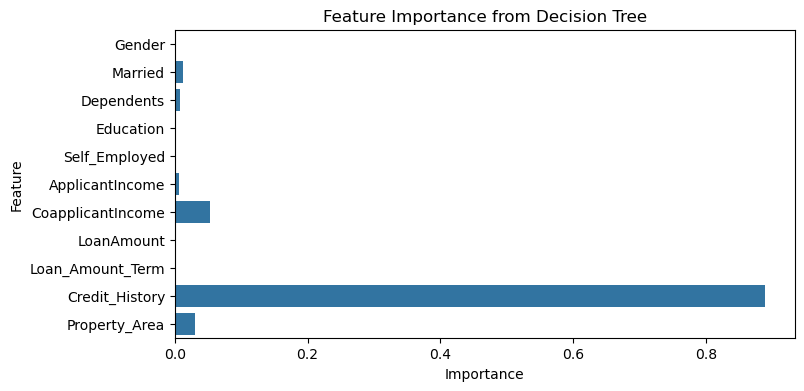

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
feature_names = X.columns
importances = dt_clf.feature_importances_
plt.figure(figsize=(8, 4))
sns.barplot(x=importances, y=feature_names)
plt.title("Feature Importance from Decision Tree")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [37]:
feature_names = X.columns
importances = rf_clf.feature_importances_
# Plot
plt.figure(figsize=(8, 4))
sns.barplot(x=importances, y=feature_names)
plt.title("Feature Importance from Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

NameError: name 'rf_clf' is not defined

In [ ]:
feature_names = X.columns
importances = gb_clf.feature_importances_
# Plot
plt.figure(figsize=(8, 4))
sns.barplot(x=importances, y=feature_names)
plt.title("Feature Importance from Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

**Support Vector Machines (SVMs)**

**Support Vector Machines (SVMs) are supervised machine learning models used
for classification and regression tasks. They work by finding the optimal
hyperplane that best separates data points into different classes or predicts
continuous values.**

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
X = np.array(
[
[0.4, -0.7],
[-1.5, -1.0],
[-1.4, -0.9],
[-1.3, -1.2],
[-1.1, -0.2],
[-1.2, -0.4],
[-0.5, 1.2],
[-1.5, 2.1],
[1.0, 1.0],
[1.3, 0.8],
[1.2, 0.5],
[0.2, -2.0],
[0.5, -2.4],
[0.2, -2.3],
[0.0, -2.7],
[1.3, 2.1],
]
)
y = np.array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1])
# Plotting settings
fig, ax = plt.subplots(figsize=(4, 3))
x_min, x_max, y_min, y_max = -3, 3, -3, 3
ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max))
# Plot samples by color and add legend
scatter = ax.scatter(X[:, 0], X[:, 1], s=150, c=y, label=y, edgecolors="k")
ax.legend(*scatter.legend_elements(), loc="upper right", title="Classes")
ax.set_title("Samples in two-dimensional feature space")
_= plt.show()

In [ ]:
from sklearn import svm
from sklearn.inspection import DecisionBoundaryDisplay


def plot_training_data_with_decision_boundary(
    kernel, ax=None, long_title=True, support_vectors=True
):
    # Train the SVC
    clf = svm.SVC(kernel=kernel, gamma=2).fit(X, y)

    # Settings for plotting
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 3))
    x_min, x_max, y_min, y_max = -3, 3, -3, 3
    ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max))

    # Plot decision boundary and margins
    common_params = {"estimator": clf, "X": X, "ax": ax}
    DecisionBoundaryDisplay.from_estimator(
        **common_params,
        response_method="predict",
        plot_method="pcolormesh",
        alpha=0.3,
    )
    DecisionBoundaryDisplay.from_estimator(
        **common_params,
        response_method="decision_function",
        plot_method="contour",
        levels=[-1, 0, 1],
        colors=["k", "k", "k"],
        linestyles=["--", "-", "--"],
    )

    if support_vectors:
        # Plot bigger circles around samples that serve as support vectors
        ax.scatter(
            clf.support_vectors_[:, 0],
            clf.support_vectors_[:, 1],
            s=150,
            facecolors="none",
            edgecolors="k",
        )

    # Plot samples by color and add legend
    ax.scatter(X[:, 0], X[:, 1], c=y, s=30, edgecolors="k")
    ax.legend(*scatter.legend_elements(), loc="upper right", title="Classes")
    if long_title:
        ax.set_title(f" Decision boundaries of {kernel} kernel in SVC")
    else:
        ax.set_title(kernel)

    if ax is None:
        plt.show()

In [ ]:
plot_training_data_with_decision_boundary("linear")
# 'linear', 'rbf', 'poly

In [ ]:
from sklearn.svm import SVC
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm, datasets

iris = datasets.load_iris()
X = iris.data[:, :2]  # we only take the first two features.
y = iris.target

def make_meshgrid(x, y, h=.02):
    x_min, x_max = x.min() - 1, x.max() + 1
    y_min, y_max = y.min() - 1, y.max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    return xx, yy

def plot_contours(ax, clf, xx, yy, **params):
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    out = ax.contourf(xx, yy, Z, **params)
    return out

model = svm.SVC(kernel='linear')
clf = model.fit(X, y)

fig, ax = plt.subplots()
# title for the plots
title = ('Decision surface of linear SVC ')
# Set-up grid for plotting.
X0, X1 = X[:, 0], X[:, 1]
xx, yy = make_meshgrid(X0, X1)

plot_contours(ax, clf, xx, yy, cmap=plt.cm.coolwarm, alpha=0.8)
ax.scatter(X0, X1, c=y, cmap=plt.cm.coolwarm, s=20, edgecolors='k')
ax.set_ylabel('y label here')
ax.set_xlabel('x label here')
ax.set_xticks(())
ax.set_yticks(())
ax.set_title(title)
ax.legend()
plt.show()

## SVC – Support Vector Classification
Simply put, Finds a decision boundary that maximizes the margin between classes.

In [36]:
X = df_filled.drop(columns=['Loan_ID', 'Loan_Status'], axis=1)
y = df_filled['Loan_Status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

In [34]:
%%time
from sklearn.svm import SVC

svc = SVC(kernel='linear')
svc.fit(X_train, y_train)

CPU times: total: 3min 38s
Wall time: 3min 47s


,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [35]:
y_pred = svc.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.37      0.54        43
           1       0.75      1.00      0.86        80

    accuracy                           0.78       123
   macro avg       0.87      0.69      0.70       123
weighted avg       0.84      0.78      0.75       123



In [38]:
# SVR Example  for Regression with California Housing

from sklearn.svm import SVR
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

# Load data
data = fetch_california_housing()
X, y = data.data[:1000], data.target[:1000]  # Use a small sample for speed

# Standardize features (SVMs are sensitive to scale)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, random_state=42)

# Train SVR
svr = SVR(kernel='rbf', C=100, gamma=0.1)
svr.fit(X_train, y_train)

# Evaluate
y_pred = svr.predict(X_test)
print("MSE:", mean_squared_error(y_test, y_pred))

MSE: 0.2214194669163513


**k-Nearest Neighbors (KNN)**

In [39]:
X = df_filled.drop(columns=['Loan_ID', 'Loan_Status'], axis=1)
y = df_filled['Loan_Status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

In [40]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3, metric='manhattan')
knn.fit(X_train, y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'manhattan'
,metric_params,None
,n_jobs,None


In [41]:
y_pred = knn.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.44      0.16      0.24        43
           1       0.66      0.89      0.76        80

    accuracy                           0.63       123
   macro avg       0.55      0.53      0.50       123
weighted avg       0.58      0.63      0.58       123



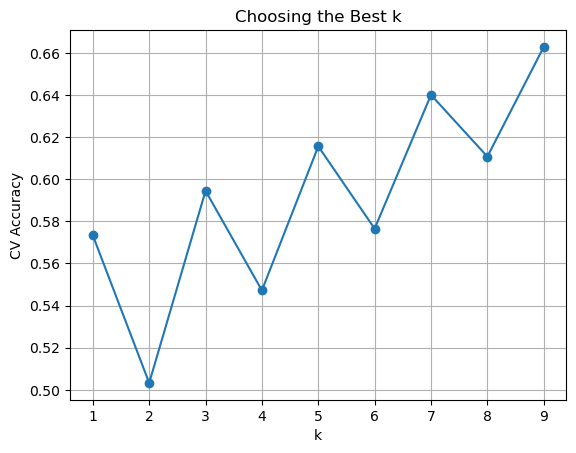

In [42]:
# Finding Optimal k with Cross-Validation

from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

k_values = list(range(1, 10))
scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, X, y, cv=5).mean()
    scores.append(score)

plt.plot(k_values, scores, marker='o')
plt.xlabel('k')
plt.ylabel('CV Accuracy')
plt.title('Choosing the Best k')
plt.grid(True)
plt.show()

In [43]:
# KNeighborsRegressor

from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

data = fetch_california_housing()
X, y = data.data, data.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

knn_reg = KNeighborsRegressor(n_neighbors=5)
knn_reg.fit(X_train, y_train)

y_pred = knn_reg.predict(X_test)
print("MSE:", mean_squared_error(y_test, y_pred))

MSE: 0.42334549078825645


In [49]:
y_pred = dt_clf.predict(X_test)

# print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

C:\Users\adeol\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


ValueError: X has 8 features, but DecisionTreeClassifier is expecting 11 features as input.

# Restraunt Revenue Prediction

In [50]:
restaurant_df = pd.read_csv('data/restaurant_data.csv')

restaurant_df.head()

,Number_of_Customers,Menu_Price,Marketing_Spend,Cuisine_Type,Average_Customer_Spending,Promotions,Reviews,Monthly_Revenue
0,61,43.117635,12.663793,Japanese,36.236133,0,45,350.912040
1,24,40.020077,4.577892,Italian,17.952562,0,36,221.319091
2,81,41.981485,4.652911,Japanese,22.600420,1,91,326.529763
3,70,43.005307,4.416053,Italian,18.984098,1,59,348.190573
4,30,17.456199,3.475052,Italian,12.766143,1,30,185.009121


**19/10/2026**

# Model Deployment & Persistence
**Persistence allows your model to be stored as a file and loaded when needed. After training and evaluating a model, you often want to:**
- Deploy it in a web/mobile app
- Reuse it in a pipeline
- Share it with others
- Save time (avoid retraining on every use)

**Saving models with joblib**
- Optimized for NumPy arrays (which Scikit-learn uses heavily)
- Faster and more memory-efficient than pickle for large models

**Saving Models with pickle: Python's built-in serialization library**
- Works with all Python objects, not just models
- However, it's slower and less efficient than joblib for large numerical arrays.

In [21]:
# Saving a model with joblib

from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import joblib

In [22]:
iris = load_iris()
X, y = iris.data, iris.target

print(iris.feature_names)
print(iris.target_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']


In [23]:
# Split the Data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)

In [24]:
# Train a Classifier. Let's use a Logistic Regression

from sklearn.linear_model import LogisticRegression

model = RandomForestClassifier()
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [25]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 1.0


In [26]:
print(y_pred)
print(y_test)

[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


In [27]:
def predict_flower(model, sepal_length, sepal_width, petal_length, petal_width):
    sample = [[sepal_length, sepal_width, petal_length, petal_width]]
    
    # Predict
    pred = model.predict(sample)[0]
    species = iris.target_names
    prediction = f'The specie of flower is {species[pred]}'
    
    return prediction

In [28]:
print(predict_flower(model, 5.1, 3.5, 1.4, 0.2))

The specie of flower is setosa


In [29]:
joblib.dump(model, 'models/rf_model.joblib')

['models/rf_model.joblib']

In [30]:
# reload the saved model

loaded_model = joblib.load('rf_model.joblib')

In [31]:
print(predict_flower(loaded_model, 5.1, 3.5, 1.4, 0.2))

The specie of flower is setosa


In [32]:
# reload the saved model

loaded_model = joblib.load('rf_model.joblib')

In [33]:
print(predict_flower(loaded_model, 5.1, 3.5, 1.4, 0.2))

The specie of flower is setosa


In [34]:
# Saving a model with pickle
import pickle

with open('models/rf_model.pkl', 'wb') as f:
    pickle.dump(model, f)

In [35]:
# load

with open('rf_model.pkl', 'rb') as f:
    loaded_pk_model = pickle.load(f)

In [36]:
print(predict_flower(loaded_pk_model, 5.1, 3.5, 1.4, 0.2))

The specie of flower is setosa


In [38]:
# Saving a Pipeline
# To persist the entire preprocessing + model pipeline

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier())
])

pipeline.fit(X_train, y_train)

joblib.dump(pipeline, 'models/rf_pipeline.joblib')

['models/rf_pipeline.joblib']